In [7]:
# Setup

from pathlib import Path

PROJECT_DIR = Path.cwd()
PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"

STUDY_AREA = "Nepal, Syabru Besi"
TARGET_CRS = "EPSG:32645"  # UTM zone 45N

print(f"Project directory: {PROJECT_DIR}")
print(f"Study area: {STUDY_AREA}")
print(f"Target CRS: {TARGET_CRS}")

Project directory: c:\Users\herol\Documents\sds320_project
Study area: Nepal, Syabru Besi
Target CRS: EPSG:32645


In [8]:
import geopandas as gpd
import rasterio
from rasterio.features import rasterize
from rasterio.transform import from_bounds
import numpy as np

#define bboxes for training, validation, and testing
bbox_train = [85.32, 28.14 ,85.36, 28.22]
bbox_val = [85.34, 28.22, 85.38, 28.25]
bbox_test = [85.36, 28.25, 85.40, 28.28] 

#transform bbox into the target CRS
from pyproj import Transformer

def from_wgs84_to_utm32465(bbox_wgs84):
    # Initialize transformer: from EPSG:4326 (WGS84) to EPSG:32645 (UTM 45N)
    # always_xy=True ensures the order is (longitude, latitude) -> (east, north)
    transformer = Transformer.from_crs("EPSG:4326", TARGET_CRS, always_xy=True)

    min_x, min_y = transformer.transform(bbox_wgs84[0], bbox_wgs84[1])
    max_x, max_y = transformer.transform(bbox_wgs84[2], bbox_wgs84[3])

    return [min_x, min_y, max_x, max_y]


bbox_train = from_wgs84_to_utm32465(bbox_train)
bbox_val = from_wgs84_to_utm32465(bbox_val)
bbox_test = from_wgs84_to_utm32465(bbox_test)

## Sentinel 2

In [9]:
# Inputs
vector_path = RAW_DATA_DIR / 'vectors' / 'nepal_flood_extent_2026-08-27.geojson'    # or .geojson
reference_path = RAW_DATA_DIR / 's2_tg' / 't1' / 'scene001' / 'B02.tif'
mask_path = PROCESSED_DATA_DIR / 'nepal_flood_extent_2026-08-27_aligned_scene.tif'

# Read polygon
gdf = gpd.read_file(vector_path)
print(gdf.total_bounds)

# Read reference raster metadata
with rasterio.open(reference_path) as src:
    ref_crs = src.crs
    if ref_crs != TARGET_CRS:
        print(f"Warning: Reference raster CRS ({ref_crs}) does not match target CRS ({TARGET_CRS}).")
    print("Reference CRS:", ref_crs)
    ref_transform = src.transform
    ref_width = src.width
    ref_height = src.height
    ref_bounds = src.bounds
    out_meta = src.meta.copy()

# Reproject vector to match raster CRS
if gdf.crs != ref_crs:
    gdf = gdf.to_crs(ref_crs)
    print(f"Reprojected gdf from {gdf.crs}to reference CRS {ref_crs}")

# Rasterize polygon to match reference raster grid
shapes = ((geom, 1) for geom in gdf.geometry if geom is not None and not geom.is_empty)

mask = rasterize(
    shapes=shapes,
    out_shape=(ref_height, ref_width),
    transform=ref_transform,
    fill=0,
    dtype=np.uint8,
    all_touched=False,
)

# Save aligned raster
out_meta.update({
    "count": 1,
    "dtype": "uint8",
    "nodata": 0,
    "compress": "lzw",
})

with rasterio.open(mask_path, "w", **out_meta) as dst:
    dst.write(mask, 1)

print("Saved:", mask_path)


[84.556395 27.79515  85.379843 28.280699]
Reference CRS: EPSG:32645
Reprojected gdf from PROJCS["WGS 84 / UTM zone 45N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",87],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32645"]]to reference CRS EPSG:32645
Saved: c:\Users\herol\Documents\sds320_project\data\processed\nepal_flood_extent_2026-08-27_aligned_scene.tif


In [7]:
str(mask_path)

'c:\\Users\\herol\\OneDrive - Universität Zürich UZH\\sds320\\project\\data\\processed\\nepal_flood_extent_2026-08-27_aligned_scene.tif'

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

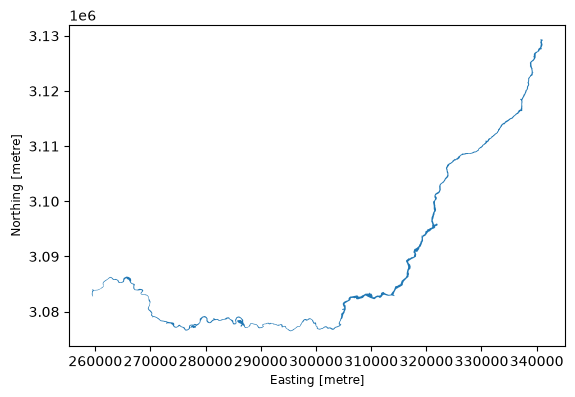

In [8]:
gdf.geometry.to_crs(ref_crs).plot()

### split into small training and val samples

In [9]:
mask

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(10980, 10980), dtype=uint8)

In [10]:
#define the input paths
bands = ["B02", "B03", "B04"]
mask_path = mask_path
before_path = RAW_DATA_DIR / 's2_tg' / 't1' / 'scene001'
after_path = RAW_DATA_DIR / 's2_tg' / 't2' / 'scene001'

#define the output paths
train_path = PROCESSED_DATA_DIR / 's2_sub_train'
val_path = PROCESSED_DATA_DIR / 's2_sub_val'
test_path = PROCESSED_DATA_DIR / 's2_sub_test'


In [11]:
from rasterio.windows import from_bounds as window_from_bounds
def clip_raster_to_bbox(input_raster_path, output_raster_path, bbox):
    with rasterio.open(input_raster_path) as src:
        # Create a window from geographic bounds using the raster's transform matrix
        geo_window = window_from_bounds(bbox[0], bbox[1], bbox[2], bbox[3], src.transform)

        # Read only the data within that calculated window
        geo_subset = src.read(1, window=geo_window)
        
        # 1. Calculate the new transform for the cropped window
        new_transform = src.window_transform(geo_window)

        # 2. Copy and update the metadata
        out_meta = src.meta.copy()
        out_meta.update({
            "driver": "GTiff",
            "height": geo_subset.shape[0],
            "width": geo_subset.shape[1],
            "transform": new_transform
        })

        # 3. Save to the output path
        with rasterio.open(output_raster_path, "w", **out_meta) as dest:
            dest.write(geo_subset, 1)




#mapping of bbox to out_path
splits = {"train": (bbox_train, train_path), "val": (bbox_val, val_path), "test": (bbox_test, test_path)}
beforeafter = {"t1": before_path, "t2": after_path}


# Clip rasters to the defined bounding boxes and save them to the respective output directories
for bbox, out_path in splits.values():
    for t in ["t1", "t2"] :
        for band in bands:
            out_path_band = out_path / t / 'scene001' / f"{band}.tif"
            if out_path_band.exists():
                print(f"File {out_path_band} already exists. Skipping.")
                continue
            out_path_band.parent.mkdir(parents=True, exist_ok=True)
            in_path = RAW_DATA_DIR / 's2_tg' / t / 'scene001' / f"{band}.tif"
            print(f"Clipping {in_path} to {out_path_band} with bbox {bbox}")
            clip_raster_to_bbox(in_path, out_path_band, bbox) #clip all RGB rasters to the bbox
            out_path_band = out_path #reset path
#same for the mask
for bbox, out_path in splits.values():
    (out_path / "mask").mkdir(parents=True, exist_ok=True)
    clip_raster_to_bbox(mask_path, out_path / "mask" / "scene001.tif", bbox) #clip mask to the bbox

File c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\data\processed\s2_sub_train\t1\scene001\B02.tif already exists. Skipping.
File c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\data\processed\s2_sub_train\t1\scene001\B03.tif already exists. Skipping.
File c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\data\processed\s2_sub_train\t1\scene001\B04.tif already exists. Skipping.
File c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\data\processed\s2_sub_train\t2\scene001\B02.tif already exists. Skipping.
File c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\data\processed\s2_sub_train\t2\scene001\B03.tif already exists. Skipping.
File c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\data\processed\s2_sub_train\t2\scene001\B04.tif already exists. Skipping.
File c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\data\processed\s2_sub_val\t1\scene001\B02.tif already exists. Skipping.
F

## preprocessing for the Sentinel-1 data

In [12]:
# Inputs
vector_path = RAW_DATA_DIR / 'vectors' / 'nepal_flood_extent_2026-08-27.geojson'    # or .geojson
reference_path = RAW_DATA_DIR / 's1_tg' / 't2' / 'scene001' / 'vh.tif'
mask_path = PROCESSED_DATA_DIR / 'nepal_flood_extent_2026-08-27_aligned_s1.tif'

# Read polygon
gdf = gpd.read_file(vector_path)

# Read reference raster metadata
with rasterio.open(reference_path) as src:
    ref_crs = src.crs
    if ref_crs != TARGET_CRS:
        print(f"Warning: Reference raster CRS ({ref_crs}) does not match target CRS ({TARGET_CRS}).")
    print("Reference CRS:", ref_crs)
    ref_transform = src.transform
    ref_width = src.width
    ref_height = src.height
    ref_bounds = src.bounds
    out_meta = src.meta.copy()

# Reproject vector to match raster CRS
if gdf.crs != ref_crs:
    gdf = gdf.to_crs(ref_crs)

# Rasterize polygon to match reference raster grid
shapes = ((geom, 1) for geom in gdf.geometry if geom is not None and not geom.is_empty)

mask = rasterize(
    shapes=shapes,
    out_shape=(ref_height, ref_width),
    transform=ref_transform,
    fill=0,
    dtype=np.uint8,
    all_touched=False,
)

# Save aligned raster
out_meta.update({
    "count": 1,
    "dtype": "uint8",
    "nodata": 0,
    "compress": "lzw",
})

with rasterio.open(mask_path, "w", **out_meta) as dst:
    dst.write(mask, 1)

print("Saved:", mask_path)


Reference CRS: EPSG:32645
Saved: c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\data\processed\nepal_flood_extent_2026-08-27_aligned_s1.tif


In [13]:
#define the input paths
bands = ["vv", "vh"]
mask_path = mask_path
before_path = RAW_DATA_DIR / 's1_tg' / 't1' / 'scene001'
after_path = RAW_DATA_DIR / 's1_tg' / 't2' / 'scene001'

#define the output paths
train_path = PROCESSED_DATA_DIR / 's1_sub_train'
val_path = PROCESSED_DATA_DIR / 's1_sub_val'
test_path = PROCESSED_DATA_DIR / 's1_sub_test'


In [14]:
from rasterio.windows import from_bounds as window_from_bounds
def clip_raster_to_bbox(input_raster_path, output_raster_path, bbox):
    with rasterio.open(input_raster_path) as src:
        # Create a window from geographic bounds using the raster's transform matrix
        geo_window = window_from_bounds(bbox[0], bbox[1], bbox[2], bbox[3], src.transform)

        # Read only the data within that calculated window
        geo_subset = src.read(1, window=geo_window)
        
        # 1. Calculate the new transform for the cropped window
        new_transform = src.window_transform(geo_window)

        # 2. Copy and update the metadata
        out_meta = src.meta.copy()
        out_meta.update({
            "driver": "GTiff",
            "height": geo_subset.shape[0],
            "width": geo_subset.shape[1],
            "transform": new_transform
        })

        # 3. Save to the output path
        with rasterio.open(output_raster_path, "w", **out_meta) as dest:
            dest.write(geo_subset, 1)




#mapping of bbox to out_path
splits = {"train": (bbox_train, train_path), "val": (bbox_val, val_path), "test": (bbox_test, test_path)}
beforeafter = {"t1": before_path, "t2": after_path}


# Clip rasters to the defined bounding boxes and save them to the respective output directories
for bbox, out_path in splits.values():
    for t in ["t1", "t2"] :
        for band in bands:
            out_path_band = out_path / t / 'scene001' / f"{band}.tif"
            if out_path_band.exists():
                print(f"File {out_path_band} already exists. Skipping.")
                continue
            out_path_band.parent.mkdir(parents=True, exist_ok=True)
            in_path = RAW_DATA_DIR / 's1_tg' / t / 'scene001' / f"{band}.tif"
            print(f"Clipping {in_path} to {out_path_band} with bbox {bbox}")
            clip_raster_to_bbox(in_path, out_path_band, bbox) #clip all RGB rasters to the bbox
            out_path_band = out_path #reset path
#same for the mask
for bbox, out_path in splits.values():
    (out_path / "mask").mkdir(parents=True, exist_ok=True)
    clip_raster_to_bbox(mask_path, out_path / "mask" / "scene001.tif", bbox) #clip mask to the bbox

File c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\data\processed\s1_sub_train\t1\scene001\vv.tif already exists. Skipping.
File c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\data\processed\s1_sub_train\t1\scene001\vh.tif already exists. Skipping.
File c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\data\processed\s1_sub_train\t2\scene001\vv.tif already exists. Skipping.
File c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\data\processed\s1_sub_train\t2\scene001\vh.tif already exists. Skipping.
File c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\data\processed\s1_sub_val\t1\scene001\vv.tif already exists. Skipping.
File c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\data\processed\s1_sub_val\t1\scene001\vh.tif already exists. Skipping.
File c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\data\processed\s1_sub_val\t2\scene001\vv.tif already exists. Skipping.
File c:\User